In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from mg_sampling.density.grid import Grid
import MDAnalysis as mda
from MDAnalysis.lib.transformations import rotation_matrix
import numpy as np
import matplotlib.pyplot as plt

from mg_sampling import PROJECT_DIR
from mg_sampling.density.utils import indices_to_mask

/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
m = Grid(PROJECT_DIR / 'density/emd_42499.map', file_format='mrc')

u = mda.Universe(PROJECT_DIR / 'density/9cbu.pdb')

/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


In [4]:
vector = np.array([10, 10, 0])
angle = np.pi / 3
axis = [0, 1, 1]
point = [x[len(x)//2] for x in m.midpoints]
M = rotation_matrix(angle, axis)
R = M[:3, :3]

m_translated = m.translate(vector)
m_rotated = m.rotate(R, point=point)

(52.27499954402447, 156.8249986320734)

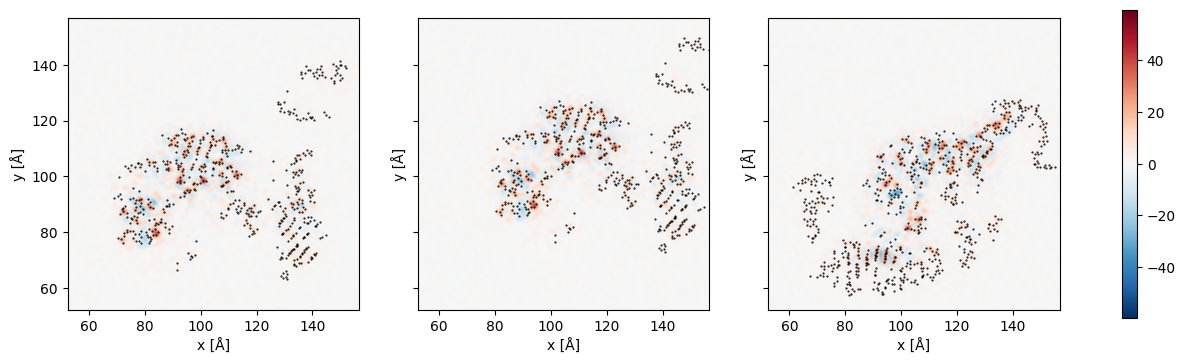

In [5]:
from matplotlib.colors import CenteredNorm

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, sharex=True, sharey=True, figsize=(16, 4))
norm = CenteredNorm()
cmap = 'RdBu_r'

L = m.midpoints[0][-1] - m.midpoints[0][0]
extent = [m.edges[0][0], m.edges[0][-1], m.edges[1][0], m.edges[1][-1]]

ag = u.select_atoms('nucleic and not type H')

mask = (ag.positions[:, 2] > L / 2 - 2) & (ag.positions[:, 2] < L / 2 + 2)
im = ax1.imshow(m.grid[:, :, len(m.grid)//2].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax1.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')

ag.translate(vector)
mask = (ag.positions[:, 2] > L / 2 - 2) & (ag.positions[:, 2] < L / 2 + 2)
ax2.imshow(m_translated.grid[:, :, len(m.grid)//2].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax2.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ag.translate(-vector)

ag.rotate(R, point=point)
mask = (ag.positions[:, 2] > L / 2 - 2) & (ag.positions[:, 2] < L / 2 + 2)
ax3.imshow(m_rotated.grid[:, :, len(m.grid)//2].T, origin='lower', norm=norm, cmap=cmap, extent=extent, interpolation='bicubic')
ax3.scatter(ag.positions[mask, 0], ag.positions[mask, 1], s=1, color='black', marker='.')
ag.rotate(R.T, point=point)

for ax in (ax1, ax2, ax3):
    ax.set_xlabel('x [Å]')
    ax.set_ylabel('y [Å]')
plt.colorbar(im, ax=(ax1, ax2, ax3))
plt.xlim(L/4, 3*L/4)
plt.ylim(L/4, 3*L/4)


In [ ]:
# Smoothing should be approximately the same if done before or after resampling
A = m.resample_factor(1.5).apply_tempfactor(100)
B = m.apply_tempfactor(100).resample_factor(1.5)

In [53]:
np.max(np.abs(A.grid - B.grid))

np.float64(0.033632394161754675)

Test our unsharpening vs. Phenix unsharpening:

```phenix.auto_sharpen emd_42499.map b_sharpen=-79.23 resolution=2.2 sharpened_map_file=emd_42499_unsharp_phenix.map```

In [9]:
m_unsharp = m.apply_tempfactor(79.23)
m_unsharp_phenix = Grid(PROJECT_DIR / 'density/emd_42499_unsharp_phenix.map', file_format='mrc')

(52.27499954402447, 156.8249986320734)

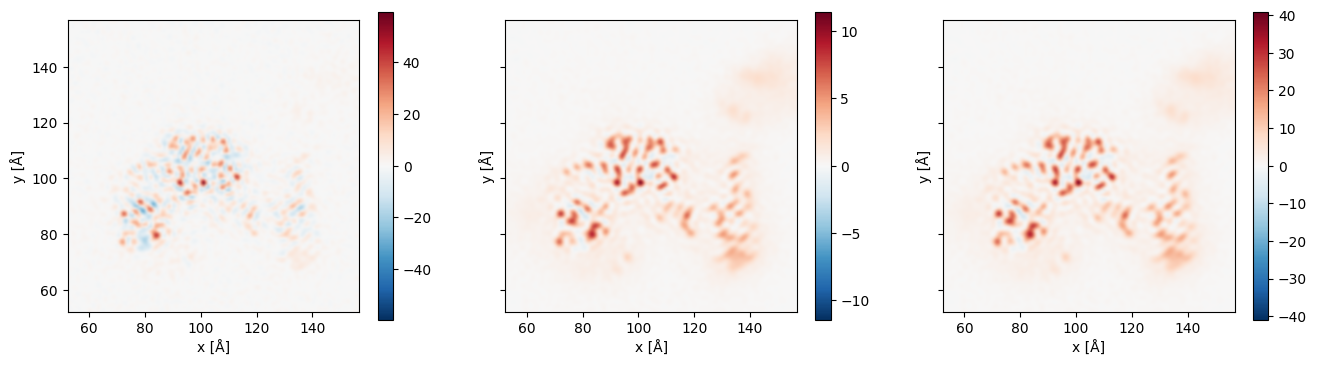

In [11]:
from matplotlib.colors import CenteredNorm

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, sharex=True, sharey=True, figsize=(16, 4))
cmap = 'RdBu_r'

L = m.midpoints[0][-1] - m.midpoints[0][0]
extent = [m.edges[0][0], m.edges[0][-1], m.edges[1][0], m.edges[1][-1]]

im = ax1.imshow(m.grid[:, :, len(m.grid)//2].T, origin='lower', norm=CenteredNorm(), cmap=cmap, extent=extent, interpolation='bicubic')
plt.colorbar(im, ax=ax1)

im = ax2.imshow(m_unsharp.grid[:, :, len(m.grid)//2].T, origin='lower', norm=CenteredNorm(), cmap=cmap, extent=extent, interpolation='bicubic')
plt.colorbar(im, ax=ax2)

im = ax3.imshow(m_unsharp_phenix.grid[:, :, len(m.grid)//2].T, origin='lower', norm=CenteredNorm(), cmap=cmap, extent=extent, interpolation='bicubic')
plt.colorbar(im, ax=ax3)

for ax in (ax1, ax2, ax3):
    ax.set_xlabel('x [Å]')
    ax.set_ylabel('y [Å]')
plt.xlim(L/4, 3*L/4)
plt.ylim(L/4, 3*L/4)


The scale is different. Maybe it's because Phenix keeps the amplitude whereas gaussian filtering is expected to reduce amplitude?

In [22]:
print("Original min-max (std):", m.grid.min(), m.grid.max(), m.grid.std())
print("Unsharp Phenix min-max (std):", m_unsharp_phenix.grid.min(), m_unsharp_phenix.grid.max(), m_unsharp_phenix.grid.std())
print("Unsharp Gaussian min-max (std):", m_unsharp.grid.min(), m_unsharp.grid.max(), m_unsharp.grid.std())


Original min-max (std): -44.264633 66.17785 1.0
Unsharp Phenix min-max (std): -13.130057 44.227283 1.0
Unsharp Gaussian min-max (std): -3.618833 12.310165 0.27737567


The map seems renormalized to keep the standard deviation at 1.0.

In [24]:
m_unsharp_normalized = m_unsharp / m_unsharp.grid.std()
print("Unsharp Gaussian min-max (normalized std):", m_unsharp_normalized.grid.min(), m_unsharp_normalized.grid.max(), m_unsharp_normalized.grid.std())

Unsharp Gaussian min-max (normalized std): -13.046685 44.38084 0.99999994


In [15]:
from mg_sampling.density.utils import voxels_around
map_params = {'dx': m.delta, 'x0': m.origin, 'nbin': m.shape}
ag = mda.Universe(PROJECT_DIR / 'density/9cbu.pdb').select_atoms("nucleic")
vox_indices = voxels_around(ag, 8, map_params)
cc_mask = indices_to_mask(vox_indices, map_params)

from scipy.stats import linregress

print("Unsharp Gaussian to sharp ref:", linregress(m_unsharp.grid[cc_mask], m.grid[cc_mask]))
print("Unsharp Phenix to sharp ref:", linregress(m_unsharp_phenix.grid[cc_mask], m.grid[cc_mask]))
print("Unsharp Gaussian to unsharp Phenix:", linregress(m_unsharp.grid[cc_mask], m_unsharp_phenix.grid[cc_mask]))

/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


Unsharp Gaussian to sharp ref: LinregressResult(slope=np.float64(3.167003950094272), intercept=np.float64(-1.5765608065903955), rvalue=np.float64(0.7587088740409886), pvalue=np.float64(0.0), stderr=np.float64(0.0030222920084992844), intercept_stderr=np.float64(0.0037242976223044646))
Unsharp Phenix to sharp ref: LinregressResult(slope=np.float64(0.8757143770789069), intercept=np.float64(-1.5713986410234337), rvalue=np.float64(0.7564245546268884), pvalue=np.float64(0.0), stderr=np.float64(0.0008416348168980328), intercept_stderr=np.float64(0.0037404669478438447))
Unsharp Gaussian to unsharp Phenix: LinregressResult(slope=np.float64(3.6054440720375696), intercept=np.float64(0.002142961324534731), rvalue=np.float64(0.9999589765567302), pvalue=np.float64(0.0), stderr=np.float64(3.62993214954058e-05), intercept_stderr=np.float64(4.473077927494284e-05))


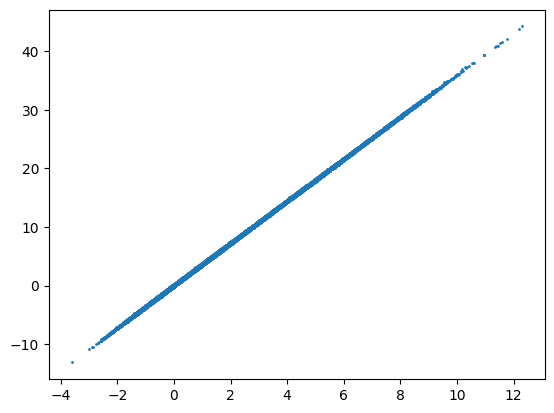

In [ ]:
plt.scatter(m_unsharp.grid[cc_mask], m_unsharp_phenix.grid[cc_mask], s=1)


The results are very similar between our unsharpening and Phenix's. Discrepancies may arise from finite precision errors.
